# Toy Model — Verification of Theorem 2 (Zero Block Structure)

Reproduces the numerical matrices in the paper (Appendix, Example).

**System:**
$$x_1(k+1) = (1 - \Delta t\,\alpha)\,x_1(k), \quad
x_2(k+1) = x_2(k) - \Delta t\,\beta\bigl(x_2(k) - x_1(k)^2\bigr)$$

with $\Delta t=0.2,\ \alpha=0.4,\ \beta=1.0$.

**Checks performed**
1. `eq:EDMD-mat-3obs` — EDMD with $\mathcal{D}_3 = \{x_1, x_2, x_1^2\}$ (exact invariant subspace)
2. `eq:EDMD-mat-9obs` — EDMD with $\mathcal{D}_9$ (degree $\le 3$ monomials), verify bottom-left $6\times 3$ zero block
3. `eq:EDMD-mat-9obs-permuted` — permuted ordering, verify two nested zero blocks
4. PageRank / PPR ordering on $K_9$ — confirm invariant subspace observables rank first


In [ ]:
import sys, os
sys.path.insert(0, '../src')

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from scipy.special import expit
from math import comb
import koopman_source as kp

np.random.seed(1234)

plt.rcParams.update({
    "font.family": "sans-serif",
    "mathtext.fontset": "cm",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "figure.dpi": 150,
    "savefig.dpi": 600,
})

SAVE_FIGS = False
FIG_DIR   = 'figures/'
os.makedirs(FIG_DIR, exist_ok=True)

# ── System parameters ─────────────────────────────────────────────────────────
dt    = 0.2
alpha = 0.4
beta  = 1.0

def toy_evolve(x):
    x_new    = x.copy()
    x_new[0] = (1 - dt * alpha) * x[0]
    x_new[1] = x[1] - dt * beta * (x[1] - x[0]**2)
    return x_new

print("Setup done.")
print(f"  dt={dt}, alpha={alpha}, beta={beta}")
print(f"  Exact K_3 diagonal: [{1-dt*alpha:.3f}, {1-dt*beta:.3f}, {(1-dt*alpha)**2:.3f}]")


Setup done.
  dt=0.2, alpha=0.4, beta=1.0
  Exact K_3 diagonal: [0.920, 0.800, 0.846]


## 1. Analytical Koopman matrix on $\mathcal{D}_3$

$$K_3 = \begin{bmatrix}
1-\Delta t\alpha & 0 & 0 \\
0 & 1-\Delta t\beta & 0 \\
0 & \Delta t\beta & (1-\Delta t\alpha)^2
\end{bmatrix}$$

(column convention: $\boldsymbol{\psi}(\mathbf{x}(k))^\top K = \boldsymbol{\psi}(\mathbf{x}(k+1))^\top$)


In [2]:
K3_exact = np.array([
    [1 - dt*alpha,  0,            0                  ],
    [0,             1 - dt*beta,  0                  ],
    [0,             dt*beta,      (1 - dt*alpha)**2  ],
])
print("Analytical K_3:")
print(np.array2string(K3_exact, precision=3, suppress_small=True))


Analytical K_3:
[[0.92  0.    0.   ]
 [0.    0.8   0.   ]
 [0.    0.2   0.846]]


## 2. EDMD with $\mathcal{D}_3$ — reproduce `eq:EDMD-mat-3obs`

In [3]:
# Monomial dictionary D3 = {x1, x2, x1^2}
# Convention: Psi rows = data points, cols = observables
# EDMD: K = pinv(Psi_X) @ Psi_Y   =>   Psi_X @ K ≈ Psi_Y

def psi_D3(x_mat):
    """x_mat: (2, M) -> Psi: (M, 3)  columns=[x1, x2, x1^2]"""
    return np.column_stack([x_mat[0], x_mat[1], x_mat[0]**2])

M = 100
x_tr = kp.data_dist(2, M, -2, 2, rndseed=1)
y_tr = kp.matrix_evolution(x_tr, toy_evolve)

Psi_X3 = psi_D3(x_tr)   # (M, 3)
Psi_Y3 = psi_D3(y_tr)

K3_edmd = kp.find_best_lin(Psi_X3, Psi_Y3)

print("EDMD K_3 (M=100, paper eq:EDMD-mat-3obs):")
print(np.array2string(K3_edmd, precision=3, suppress_small=True))
print()
print("Analytical K_3:")
print(np.array2string(K3_exact, precision=3, suppress_small=True))
print()
print(f"Max entry-wise error: {np.max(np.abs(K3_edmd - K3_exact)):.4f}")


EDMD K_3 (M=100, paper eq:EDMD-mat-3obs):
[[ 0.92  -0.    -0.   ]
 [-0.     0.8   -0.   ]
 [-0.     0.2    0.846]]

Analytical K_3:
[[0.92  0.    0.   ]
 [0.    0.8   0.   ]
 [0.    0.2   0.846]]

Max entry-wise error: 0.0000


## 3. EDMD with $\mathcal{D}_9$ — reproduce `eq:EDMD-mat-9obs`

In [4]:
# D9 = all monomials of degree <= 3 in (x1, x2)
# Ordering: x1, x2, x1^2, x1x2, x2^2, x1^3, x1^2x2, x1x2^2, x2^3
OBS_NAMES_9 = ['x1', 'x2', 'x1^2', 'x1x2', 'x2^2',
               'x1^3', 'x1^2x2', 'x1x2^2', 'x2^3']

def psi_D9(x_mat):
    """x_mat: (2, M) -> Psi: (M, 9)"""
    x1, x2 = x_mat[0], x_mat[1]
    return np.column_stack([
        x1, x2, x1**2, x1*x2, x2**2,
        x1**3, x1**2*x2, x1*x2**2, x2**3
    ])

M9 = 2000
x9 = kp.data_dist(2, M9, -2, 2, rndseed=1)
y9 = kp.matrix_evolution(x9, toy_evolve)

Psi_X9 = psi_D9(x9)
Psi_Y9 = psi_D9(y9)
K9     = kp.find_best_lin(Psi_X9, Psi_Y9)

print("EDMD K_9  (M=2000):")
header = '        ' + ''.join(f'{n:>10s}' for n in OBS_NAMES_9)
print(header)
for i, row in enumerate(K9):
    print(f'{OBS_NAMES_9[i]:>8s}' + ''.join(f'{v:10.3f}' for v in row))


EDMD K_9  (M=2000):
                x1        x2      x1^2      x1x2      x2^2      x1^3    x1^2x2    x1x2^2      x2^3
      x1     0.920    -0.000    -0.000    -0.000    -0.001    -0.000    -0.003    -0.161    -0.004
      x2    -0.000     0.800    -0.000    -0.000    -0.002     0.000    -0.009    -0.016    -0.107
    x1^2    -0.000     0.200     0.846    -0.000     0.122     0.000     0.517    -0.009     0.420
    x1x2    -0.000     0.000     0.000     0.736    -0.002     0.000    -0.007     0.705    -0.021
    x2^2    -0.000    -0.000     0.000     0.000     0.626     0.000    -0.061     0.002     0.309
    x1^3     0.000     0.000     0.000     0.184     0.001     0.779     0.003     0.171     0.005
  x1^2x2     0.000     0.000     0.000    -0.000     0.321    -0.000     0.683     0.007     0.321
  x1x2^2     0.000    -0.000    -0.000     0.000     0.000     0.000     0.000     0.592     0.006
    x2^3     0.000     0.000     0.000     0.000     0.000    -0.000     0.001     0.007 

### Verify bottom-left $6 \times 3$ zero block

In column convention, $K$ acts as $\boldsymbol{\psi}^\top K$.
The invariant subspace $\mathcal{D}_3 = \{x_1, x_2, x_1^2\}$ occupies the first 3 columns/rows.
Zero block condition: rows 4–9, columns 1–3 of $K$ should be $= 0$.


In [5]:
zero_block = K9[3:, :3]   # rows 3..8, cols 0..2  (0-indexed)
print("Bottom-left 6x3 block (should be ~0):")
print(np.array2string(zero_block, precision=3, suppress_small=True))
print(f"\nMax absolute value in zero block: {np.max(np.abs(zero_block)):.4f}")

# Also verify top-left 3x3 matches K3
print("\nTop-left 3x3 block:")
print(np.array2string(K9[:3, :3], precision=3, suppress_small=True))
print("\nK3_exact:")
print(np.array2string(K3_exact, precision=3, suppress_small=True))
print(f"Max difference: {np.max(np.abs(K9[:3,:3] - K3_exact)):.4f}")


Bottom-left 6x3 block (should be ~0):
[[-0.  0.  0.]
 [-0. -0.  0.]
 [ 0.  0.  0.]
 [ 0.  0.  0.]
 [ 0. -0. -0.]
 [ 0.  0.  0.]]

Max absolute value in zero block: 0.0000

Top-left 3x3 block:
[[ 0.92  -0.    -0.   ]
 [-0.     0.8   -0.   ]
 [-0.     0.2    0.846]]

K3_exact:
[[0.92  0.    0.   ]
 [0.    0.8   0.   ]
 [0.    0.2   0.846]]
Max difference: 0.0000


## 4. Permuted ordering — reproduce `eq:EDMD-mat-9obs-permuted`

In [6]:
# Permutation: x1, x1x2, x1^3, x2, x1^2, x2^2, x1^2x2, x1x2^2, x2^3
# Original indices in D9:
#   x1=0, x2=1, x1^2=2, x1x2=3, x2^2=4, x1^3=5, x1^2x2=6, x1x2^2=7, x2^3=8
PERM = [0, 3, 5, 1, 2, 4, 6, 7, 8]
PERM_NAMES = [OBS_NAMES_9[i] for i in PERM]

K9p = K9[np.ix_(PERM, PERM)]

print("Permuted EDMD K_9 (eq:EDMD-mat-9obs-permuted):")
header = '          ' + ''.join(f'{n:>10s}' for n in PERM_NAMES)
print(header)
for i, row in enumerate(K9p):
    print(f'{PERM_NAMES[i]:>10s}' + ''.join(f'{v:10.3f}' for v in row))

# Zero block checks
print("\n--- Zero block checks ---")
# Block 1: bottom-left 6x3  (rows 3..8, cols 0..2)
b1 = K9p[3:, :3]
print(f"6x3 bottom-left (rows 4-9, cols 1-3): max|.| = {np.max(np.abs(b1)):.4f}")

# Block 2: bottom-left 4x5  (rows 5..8, cols 0..4)
b2 = K9p[5:, :5]
print(f"4x5 bottom-left (rows 6-9, cols 1-5): max|.| = {np.max(np.abs(b2)):.4f}")


Permuted EDMD K_9 (eq:EDMD-mat-9obs-permuted):
                  x1      x1x2      x1^3        x2      x1^2      x2^2    x1^2x2    x1x2^2      x2^3
        x1     0.920    -0.000    -0.000    -0.000    -0.000    -0.001    -0.003    -0.161    -0.004
      x1x2    -0.000     0.736     0.000     0.000     0.000    -0.002    -0.007     0.705    -0.021
      x1^3     0.000     0.184     0.779     0.000     0.000     0.001     0.003     0.171     0.005
        x2    -0.000    -0.000     0.000     0.800    -0.000    -0.002    -0.009    -0.016    -0.107
      x1^2    -0.000    -0.000     0.000     0.200     0.846     0.122     0.517    -0.009     0.420
      x2^2    -0.000     0.000     0.000    -0.000     0.000     0.626    -0.061     0.002     0.309
    x1^2x2     0.000    -0.000    -0.000     0.000     0.000     0.321     0.683     0.007     0.321
    x1x2^2     0.000     0.000     0.000    -0.000    -0.000     0.000     0.000     0.592     0.006
      x2^3     0.000     0.000    -0.000    

## 5. Heatmap visualization — all four orderings

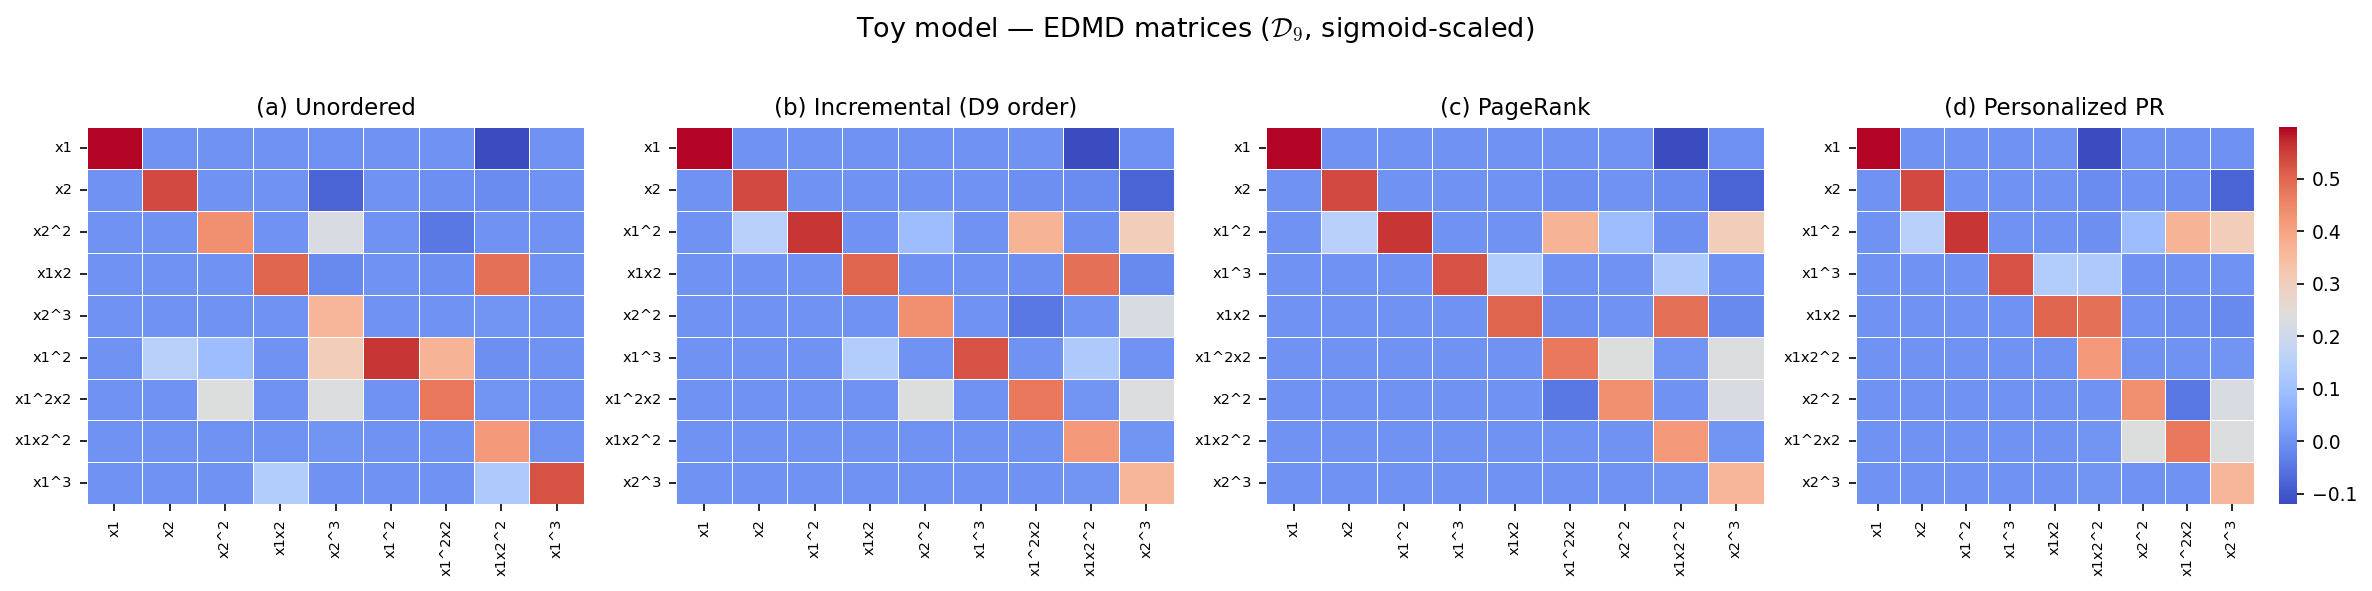

In [7]:
# PageRank / PPR orderings on K9
default_basis = np.array([0, 1])   # x1, x2 are the state coordinates (index in D9)

methods_toy = kp.compute_orderings(K9, 9, 2, default_basis, Psi_X9, Psi_Y9)

# Manual orderings to also show the paper permutation
methods_toy['Incremental'] = np.arange(9)
methods_toy['Permuted']    = np.array(PERM)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
scale = 1.5

panels = [
    ('Unordered',   '(a) Unordered'),
    ('Incremental', '(b) Incremental (D9 order)'),
    ('PageRank',    '(c) PageRank'),
    ('PPR',         '(d) Personalized PR'),
]

for ax, (name, label) in zip(axes, panels):
    o      = methods_toy[name]
    K_perm = K9[np.ix_(o, o)]
    names_perm = [OBS_NAMES_9[i] for i in o]
    show_cbar  = (name == 'PPR')
    sns.heatmap(-1 + 2*expit(K_perm * scale), ax=ax, cmap='coolwarm',
                cbar=show_cbar, xticklabels=names_perm, yticklabels=names_perm,
                linewidths=0.3, linecolor='white')
    ax.set_title(label, fontsize=11)
    ax.tick_params(axis='both', labelsize=7)

plt.suptitle('Toy model — EDMD matrices ($\mathcal{D}_9$, sigmoid-scaled)', fontsize=13, y=1.02)
plt.tight_layout()
if SAVE_FIGS:
    plt.savefig(f'{FIG_DIR}toy_D9_heatmap.pdf', dpi=600, bbox_inches='tight')
plt.show()
